In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
homes = pd.read_csv("boston_homes_final.csv")

neighborhood_values = (homes.groupby("CITY")["TOTAL_VALUE"]
                       .agg(["mean", "median"])
                       .sort_values("median", ascending=False)
                       .reset_index())

neighborhood_values

,CITY,mean,median
0,BROOKLINE,1.193853e+06,1120400.0
1,CHARLESTOWN,1.034326e+06,900700.0
2,BOSTON,1.408092e+06,879000.0
3,SOUTH BOSTON,9.367495e+05,832650.0
4,ROXBURY CROSSING,1.093619e+06,822600.0
5,JAMAICA PLAIN,9.023814e+05,799300.0
6,WEST ROXBURY,7.610440e+05,740600.0
7,DORCHESTER,7.473565e+05,724200.0
8,NEWTON,7.062000e+05,706200.0
9,ROSLINDALE,7.122101e+05,701900.0


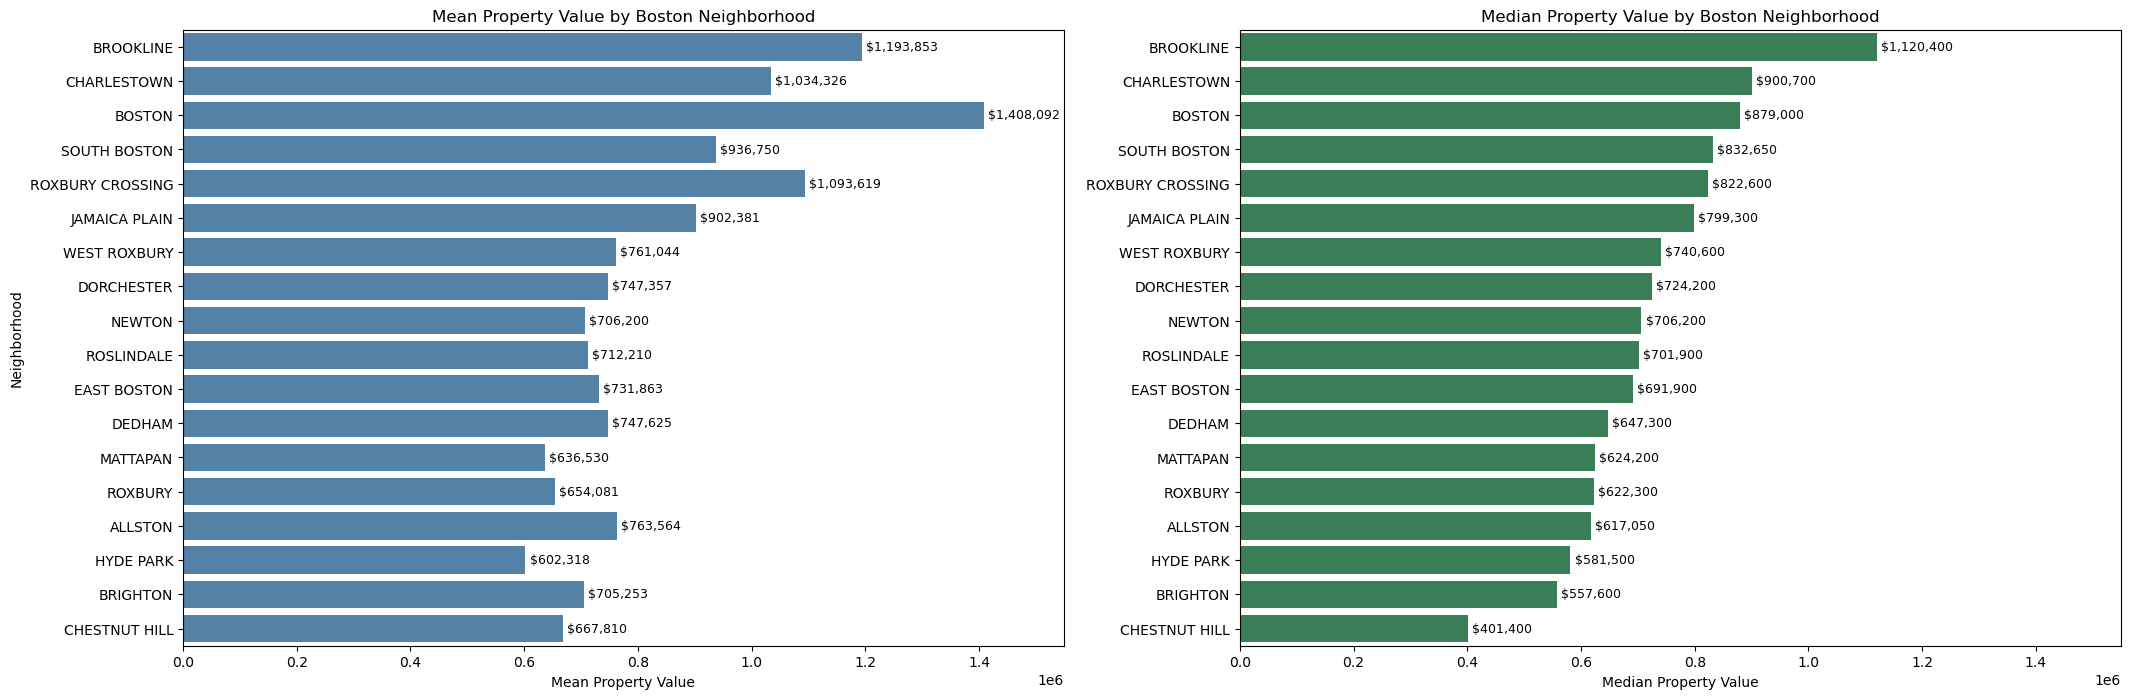

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(25, 8))

sns.barplot(data=neighborhood_values, x="mean", y="CITY", color="steelblue", 
            ax=axes[0])

axes[0].set_title("Mean Property Value by Boston Neighborhood")
axes[0].set_xlabel("Mean Property Value")
axes[0].set_ylabel("Neighborhood")

sns.barplot(data=neighborhood_values, x="median", y="CITY", color="seagreen",
            ax=axes[1])

axes[1].set_title("Median Property Value by Boston Neighborhood")
axes[1].set_xlabel("Median Property Value")
axes[1].set_ylabel("")

max_value = neighborhood_values[["mean", "median"]].max().max()
axes[0].set_xlim(0, max_value*1.1)
axes[1].set_xlim(0, max_value*1.1)

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, labels=[f'${bar.get_width():,.0f}' for bar in container],
        padding=3, fontsize=9)

plt.show()

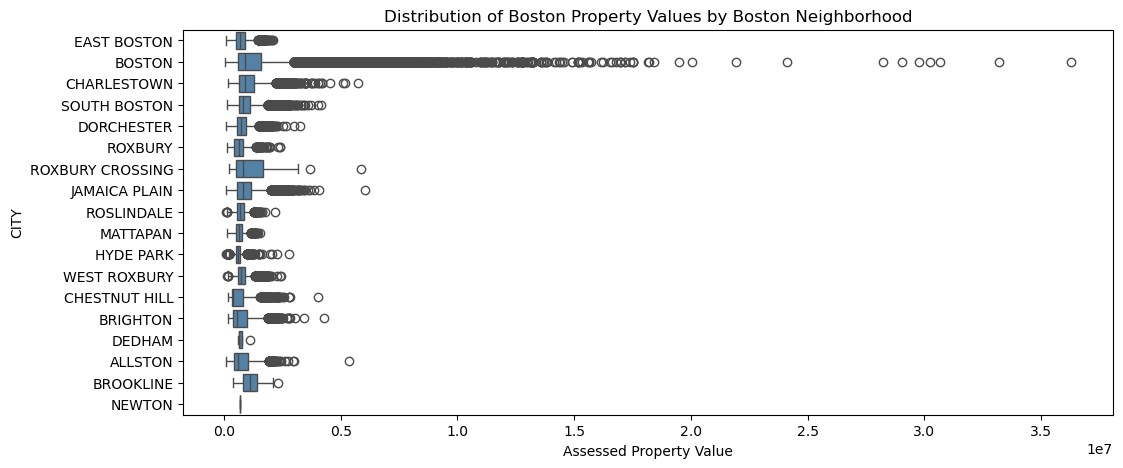

In [32]:
plt.figure(figsize=(12,5))

sns.boxplot(data=homes, x="TOTAL_VALUE", y="CITY", color="steelblue")

plt.title("Distribution of Boston Property Values by Boston Neighborhood")
plt.xlabel("Assessed Property Value")

plt.show()

We chose to use median property value instead of the mean because property values can be skewed by extremely expensive properties. The median is less affected by these outliers and provides a more accurate representation of a typical property's assessed value within each neighborhood. This allows for a more meaningful comparison of property values across Boston neighborhoods and helps us better understand how location relates to property value.

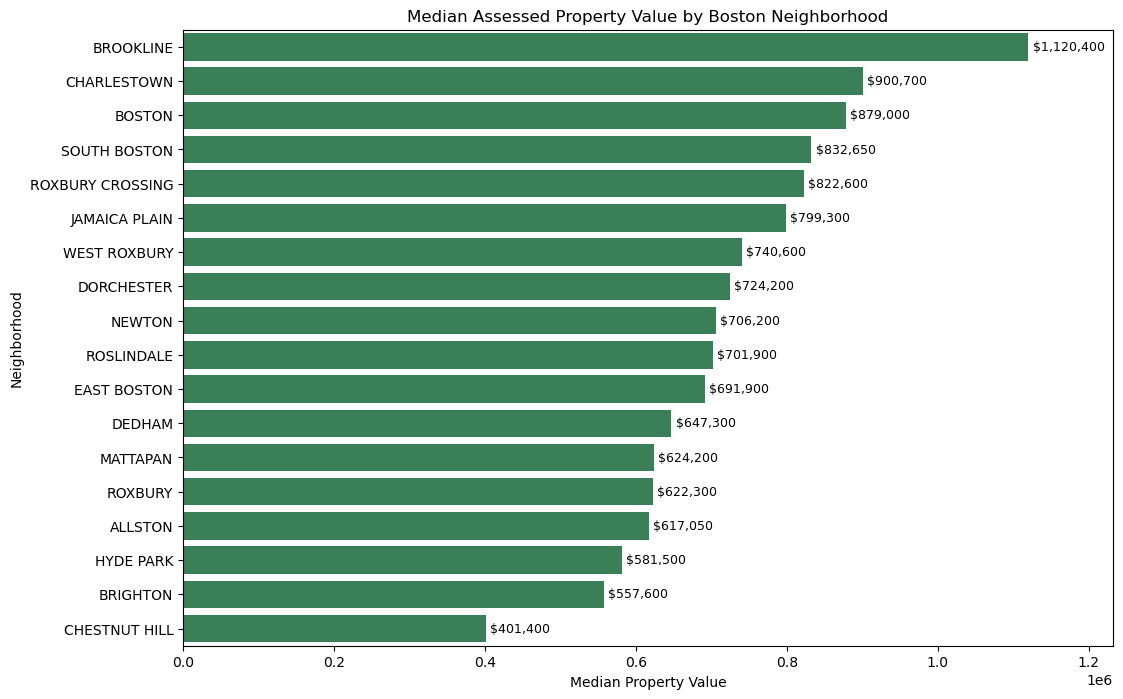

In [28]:
plt.figure(figsize=(12,8))

ax = sns.barplot(data=neighborhood_values, x="median", y="CITY", color="seagreen")

for container in ax.containers:
        ax.bar_label(container, labels=[f'${bar.get_width():,.0f}' for bar in container],
        padding=3, fontsize=9)

maximum = neighborhood_values["median"].max()
ax.set_xlim(0, maximum*1.1)

plt.title("Median Assessed Property Value by Boston Neighborhood")
plt.xlabel("Median Property Value")
plt.ylabel("Neighborhood")

plt.show()